Step 1:
  Residual MSE: 0.5351
  Update MSE: 0.0203
Step 2:
  Residual MSE: 0.4373
  Update MSE: 0.0154
Step 3:
  Residual MSE: 0.3572
  Update MSE: 0.0195
Step 4:
  Residual MSE: 0.2930
  Update MSE: 0.0201
Step 5:
  Residual MSE: 0.2411
  Update MSE: 0.0127


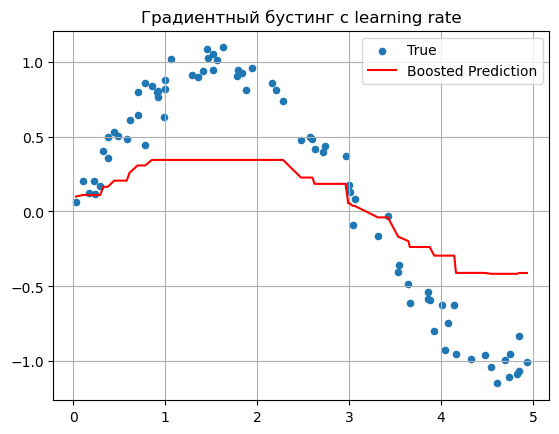

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor

# Генерация данных
np.random.seed(42)
X = np.sort(5 * np.random.rand(80, 1), axis=0)
y = np.sin(X).ravel() + np.random.normal(0, 0.1, X.shape[0])

# Начальное предсказание — нули
y_pred = np.zeros_like(y)

# Параметры бустинга
n_estimators = 5               # Количество деревьев (итераций)
learning_rate = 0.1            # Коэффициент обучения (влияние каждого дерева)

models = []  # Список для хранения деревьев

# Основной цикл градиентного бустинга
for i in range(n_estimators):
    # Вычисляем текущие ошибки
    residuals = y - y_pred
    
    # Обучаем дерево на этих ошибках
    tree = DecisionTreeRegressor(max_depth=3)
    tree.fit(X, residuals)
    models.append(tree)
    
    # Предсказание дерева
    update = tree.predict(X)
    
    # Обновляем общее предсказание с учетом learning rate
    y_pred += learning_rate * update
    
    # Вывод информации о прогрессе
    print(f"Step {i+1}:")
    print(f"  Residual MSE: {np.mean(residuals**2):.4f}")
    print(f"  Update MSE: {np.mean((update - residuals)**2):.4f}")

# Визуализация результата
plt.scatter(X, y, s=20, label="True")
plt.plot(X, y_pred, color="red", label="Boosted Prediction")
plt.title("Градиентный бустинг с learning rate")
plt.legend()
plt.grid(True)
plt.show()
